In [2]:
import os 
import numpy as np
import re
import matplotlib.pyplot as plt
import torch
import pandas as pd
from scipy.optimize import minimize
from IPython.display import display, Markdown
from pathlib import Path

In [3]:
%cd Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/feedforward

/home/bergmann/Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/feedforward


In [ ]:
base_log_dir = Path("/home/bergmann/Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/feedforward/logs")

experiment_names = ["feedforward_kin8nm_uS_nS_10epochs_10runs", "feedforward_kin8nm_uS_nS_10epochs_10runs_cesistacoeffs"]
"""
experiment_names = [
    "feedforward_kin8nm_SGD_nS_10epochs_10runs", 
    "feedforward_kin8nm_AdamW_nS_10epochs_10runs", 
    "feedforward_kin8nm_uS_nS_10epochs_10runs"
]
"""
df_metrics = []

for experiment_name in experiment_names:
    target_dir = base_log_dir / experiment_name
    log_file_path = target_dir / "log.pt"

    print(f"Zieldatei-Pfad:      {log_file_path}")
    print(f"Existiert die Datei? {log_file_path.exists()}")

    if log_file_path.exists():
        data = torch.load(log_file_path, weights_only=False)
        history_list = data.get("history", [])
        
        df_metrics.append(pd.DataFrame(history_list))

Zieldatei-Pfad:      /home/bergmann/Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/feedforward/logs/feedforward_kin8nm_SGD_nS_10epochs_10runs/log.pt
Existiert die Datei? True
Zieldatei-Pfad:      /home/bergmann/Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/feedforward/logs/feedforward_kin8nm_AdamW_nS_10epochs_10runs/log.pt
Existiert die Datei? True
Zieldatei-Pfad:      /home/bergmann/Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/feedforward/logs/feedforward_kin8nm_uS_nS_10epochs_10runs/log.pt
Existiert die Datei? True


In [43]:
def extract_experiment_data(df, group_index):
    # 1. Nach Schicht filtern
    layer_df = df[df["layer_index"] == group_index]
    
    if layer_df.empty:
        raise ValueError(f"Keine Daten für group_index {group_index} gefunden.")
        
    layer_name = layer_df["layer_name"].iloc[0]
    param_size = layer_df["param_size"].iloc[0]

    avg_df = layer_df.groupby("epoch", as_index=False).mean(numeric_only=True)

    avg_df = avg_df.sort_values("epoch")
        
    step_values = avg_df["epoch"].values
    norm_grad_values = avg_df["norm_grad"].values if "norm_grad" in avg_df.columns else None
    loss_values = avg_df["loss"].values
    
    return step_values, norm_grad_values, layer_name, param_size, loss_values



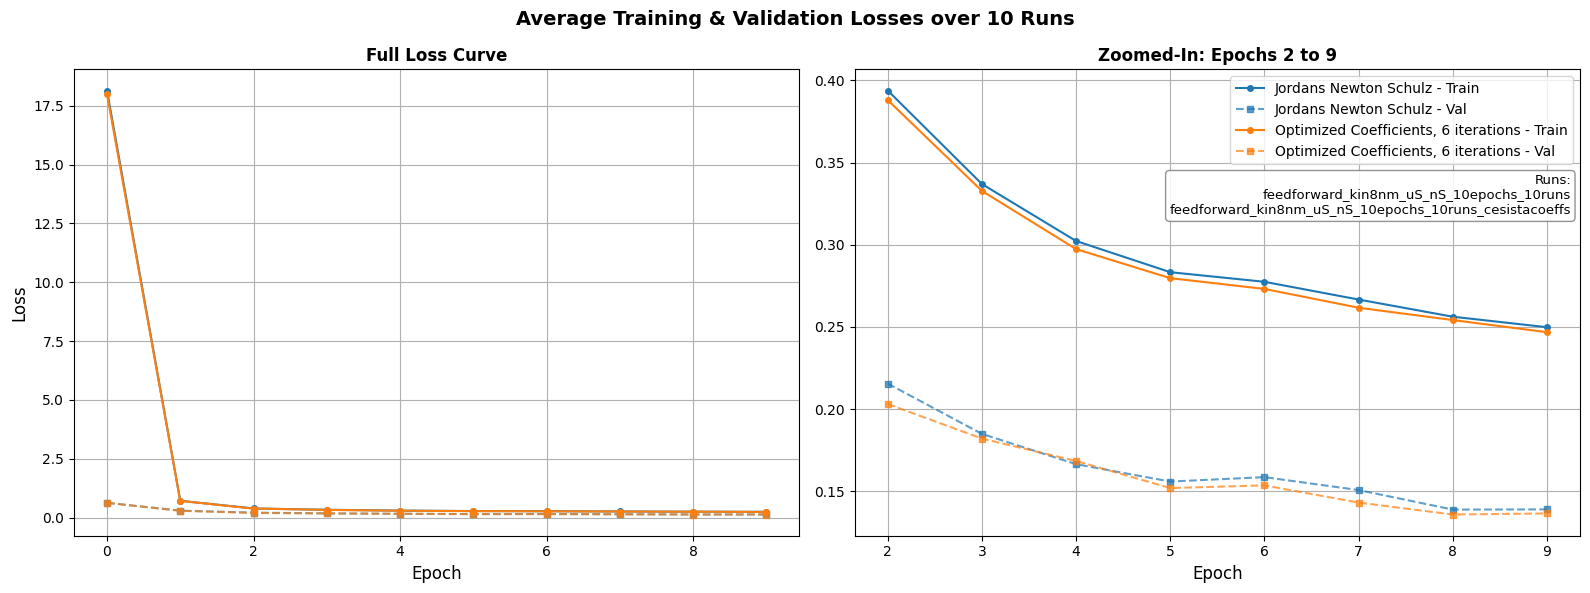

In [50]:
layer_index = 0 # any layer suffices
informal_experiment_names = ["Jordans Newton Schulz", "Optimized Coefficients, 6 iterations"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

markersize = 4
colors = ['#1f77b4', '#ff7f0e']

for idx, (informal_name, experiment, exp_key) in enumerate(zip(informal_experiment_names, df_metrics, experiment_names)):
    step_values, norm_grad_values, layer_name, param_size, loss_values = extract_experiment_data(experiment, layer_index)
    x = np.array(step_values)
    color = colors[idx % len(colors)]
    
    raw_data = torch.load(base_log_dir / exp_key / "log.pt", weights_only=False)
    val_losses = raw_data.get("validation_losses", [])
    
    ax1.plot(x, loss_values, 'o-', color=color, markersize=markersize, label=f"{informal_name} - Train")
    if val_losses:
        ax1.plot(np.arange(len(val_losses)), val_losses, 's--', color=color, alpha=0.7, markersize=markersize, label=f"{informal_name} - Val")
        
    ax2.plot(x[2:], loss_values[2:], 'o-', color=color, markersize=markersize, label=f"{informal_name} - Train")
    if val_losses:
        ax2.plot(np.arange(2, len(val_losses)), val_losses[2:], 's--', color=color, alpha=0.7, markersize=markersize, label=f"{informal_name} - Val")

ax1.set_title("Full Loss Curve", fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.grid(True)

ax2.set_title("Zoomed-In: Epochs 2 to 9", fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.grid(True)

leg = ax2.legend(fontsize=10, loc='upper right')
fig.canvas.draw()

bbox = leg.get_window_extent().transformed(ax2.transAxes.inverted())

runs_text = "Runs:\n" + "\n".join(experiment_names)
ax2.text(
    bbox.x1, bbox.y0 - 0.02, runs_text, 
    transform=ax2.transAxes, 
    ha='right', va='top', 
    fontsize=9.5, 
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray')
)

plt.suptitle("Average Training & Validation Losses over 10 Runs", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [42]:
for name, df in zip(experiment_names, df_metrics):
    print(f"Spalten für {name}: {df.columns.tolist()}")

Spalten für feedforward_kin8nm_uS_nS_10epochs_10runs: ['epoch', 'layer_index', 'layer_name', 'param_size', 'norm_grad', 'L_estimated', 'loss']
Spalten für feedforward_kin8nm_uS_nS_10epochs_10runs_cesistacoeffs: ['epoch', 'layer_index', 'layer_name', 'param_size', 'norm_grad', 'L_estimated', 'loss']


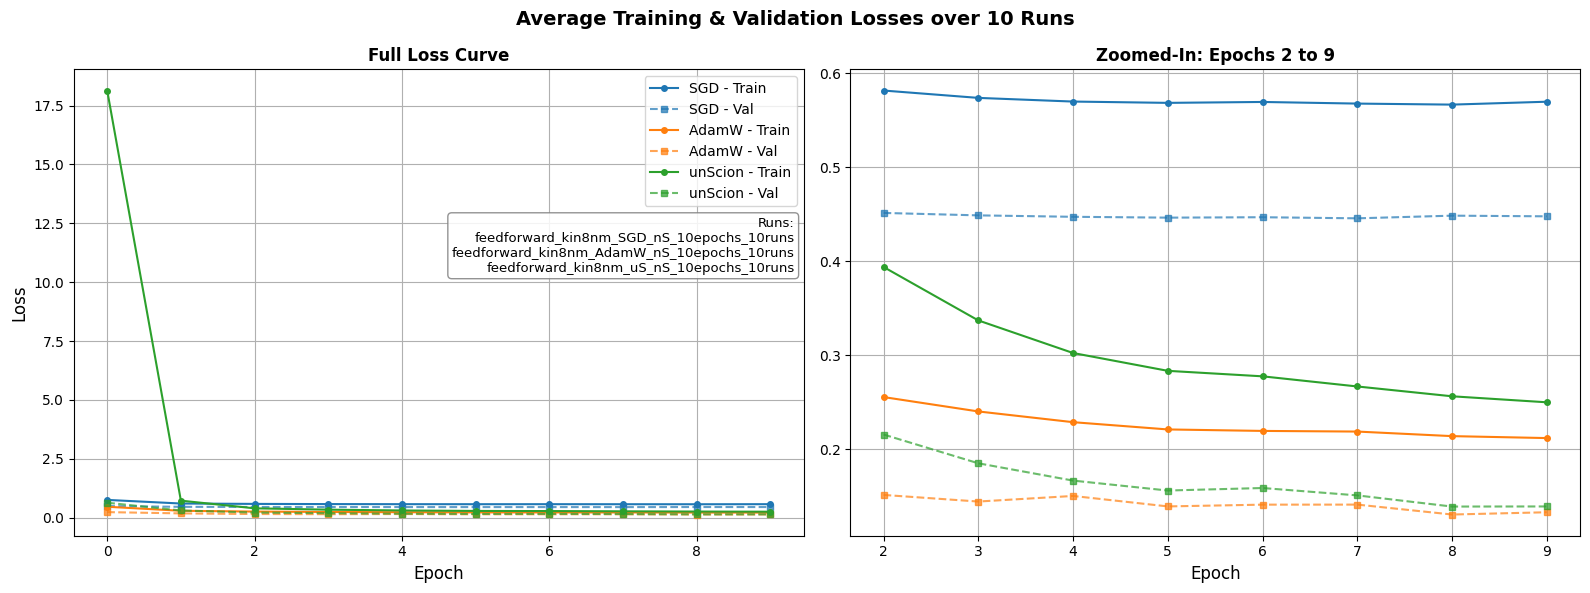

In [63]:


informal_experiment_names = ["SGD", "AdamW", "unScion"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

markersize = 4
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for idx, (informal_name, experiment, exp_key) in enumerate(zip(informal_experiment_names, df_metrics, experiment_names)):
    step_values, norm_grad_values, layer_name, param_size, loss_values = extract_experiment_data(experiment, layer_index)
    x = np.array(step_values)
    color = colors[idx % len(colors)]
    
    raw_data = torch.load(base_log_dir / exp_key / "log.pt", weights_only=False)
    val_losses = raw_data.get("validation_losses", [])
    
    ax1.plot(x, loss_values, 'o-', color=color, markersize=markersize, label=f"{informal_name} - Train")
    if val_losses:
        ax1.plot(np.arange(len(val_losses)), val_losses, 's--', color=color, alpha=0.7, markersize=markersize, label=f"{informal_name} - Val")
        
    ax2.plot(x[2:], loss_values[2:], 'o-', color=color, markersize=markersize, label=f"{informal_name} - Train")
    if val_losses:
        ax2.plot(np.arange(2, len(val_losses)), val_losses[2:], 's--', color=color, alpha=0.7, markersize=markersize, label=f"{informal_name} - Val")

ax1.set_title("Full Loss Curve", fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.grid(True)

ax2.set_title("Zoomed-In: Epochs 2 to 9", fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.grid(True)

leg = ax1.legend(fontsize=10, loc='upper right')
fig.canvas.draw()

bbox = leg.get_window_extent().transformed(ax1.transAxes.inverted())

runs_text = "Runs:\n" + "\n".join(experiment_names)
ax1.text(
    bbox.x1, bbox.y0 - 0.02, runs_text, 
    transform=ax1.transAxes, 
    ha='right', va='top', 
    fontsize=9.5, 
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray')
)

plt.suptitle("Average Training & Validation Losses over 10 Runs", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()